# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Caffeine Crash and Anxiety Telemetry Dataset](https://www.kaggle.com/datasets/samartalwar/caffeine-crash-and-jitters-energy-drinks-and-anxiety)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('caffeine_crash_and_anxiety_telemetry.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


## last Five row

In [4]:
df.tail()

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
7995,CAF-07996,25,Male,Slow,Moderate,1.8,7.3,1.32,Energy Drink (Sugar-Free),165,0.0,15,8.3,3.8,3.1,4.9,4.1,Mild Afternoon Fatigue
7996,CAF-07997,23,Female,Normal,Moderate,1.0,7.3,0.72,Brewed Drip Coffee,162,5.0,40,2.0,1.2,1.0,6.1,5.0,Mild Afternoon Fatigue
7997,CAF-07998,29,Female,Normal,Low,2.6,5.0,1.06,Brewed Drip Coffee,178,9.8,37,8.3,4.3,4.8,5.4,6.2,Moderate Crash & Lethargy
7998,CAF-07999,52,Female,Fast,Low,1.0,5.7,3.63,Energy Drink (Full Sugar),185,59.8,34,2.0,3.2,3.0,7.1,5.9,Moderate Crash & Lethargy
7999,CAF-08000,20,Female,Normal,Moderate,4.6,6.7,1.19,Energy Drink (Sugar-Free),214,0.0,12,5.4,2.5,3.5,6.6,6.5,Moderate Crash & Lethargy


## Shape of our dataset

In [5]:
df.shape

(8000, 18)

## List out all columns

In [6]:
df.columns

Index(['user_id', 'age', 'gender', 'cyp1a2_metabolizer_type',
       'caffeine_tolerance', 'baseline_anxiety_score', 'prior_sleep_hours',
       'daily_hydration_liters', 'primary_caffeine_source', 'caffeine_mg',
       'sugar_grams', 'consumption_duration_min', 'heart_rate_spike_bpm',
       'jitters_intensity_score', 'acute_anxiety_score', 'crash_onset_hours',
       'crash_severity_score', 'crash_risk_level'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

user_id                      object
age                           int64
gender                       object
cyp1a2_metabolizer_type      object
caffeine_tolerance           object
baseline_anxiety_score      float64
prior_sleep_hours           float64
daily_hydration_liters      float64
primary_caffeine_source      object
caffeine_mg                   int64
sugar_grams                 float64
consumption_duration_min      int64
heart_rate_spike_bpm        float64
jitters_intensity_score     float64
acute_anxiety_score         float64
crash_onset_hours           float64
crash_severity_score        float64
crash_risk_level             object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8000 non-null   object 
 1   age                       8000 non-null   int64  
 2   gender                    8000 non-null   object 
 3   cyp1a2_metabolizer_type   8000 non-null   object 
 4   caffeine_tolerance        8000 non-null   object 
 5   baseline_anxiety_score    8000 non-null   float64
 6   prior_sleep_hours         8000 non-null   float64
 7   daily_hydration_liters    8000 non-null   float64
 8   primary_caffeine_source   8000 non-null   object 
 9   caffeine_mg               8000 non-null   int64  
 10  sugar_grams               8000 non-null   float64
 11  consumption_duration_min  8000 non-null   int64  
 12  heart_rate_spike_bpm      8000 non-null   float64
 13  jitters_intensity_score   8000 non-null   float64
 14  acute_an

## Check Null Value

In [9]:
df.isnull().sum()

user_id                     0
age                         0
gender                      0
cyp1a2_metabolizer_type     0
caffeine_tolerance          0
baseline_anxiety_score      0
prior_sleep_hours           0
daily_hydration_liters      0
primary_caffeine_source     0
caffeine_mg                 0
sugar_grams                 0
consumption_duration_min    0
heart_rate_spike_bpm        0
jitters_intensity_score     0
acute_anxiety_score         0
crash_onset_hours           0
crash_severity_score        0
crash_risk_level            0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,age,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score
count,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,32.950875,3.48855,6.375550,2.108222,198.044125,18.026025,28.976250,4.669675,3.323437,3.683588,5.648900,6.294100
std,11.513711,2.07950,1.292857,0.783542,65.865873,19.132112,20.488751,4.004456,2.310030,2.370665,1.394713,2.334954
min,18.000000,1.00000,3.200000,0.600000,40.000000,0.000000,3.000000,2.000000,1.000000,1.000000,1.500000,1.000000
25%,24.000000,1.80000,5.500000,1.560000,157.000000,0.800000,10.000000,2.000000,1.300000,1.700000,4.500000,4.600000
50%,30.000000,3.00000,6.400000,2.110000,195.000000,10.500000,26.000000,2.500000,2.700000,3.200000,5.700000,6.400000
75%,40.000000,4.60000,7.300000,2.650000,234.000000,34.600000,45.000000,6.200000,4.500000,5.100000,6.900000,8.100000
max,65.000000,9.50000,9.500000,4.800000,420.000000,62.000000,107.000000,35.700000,10.000000,10.000000,7.500000,10.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

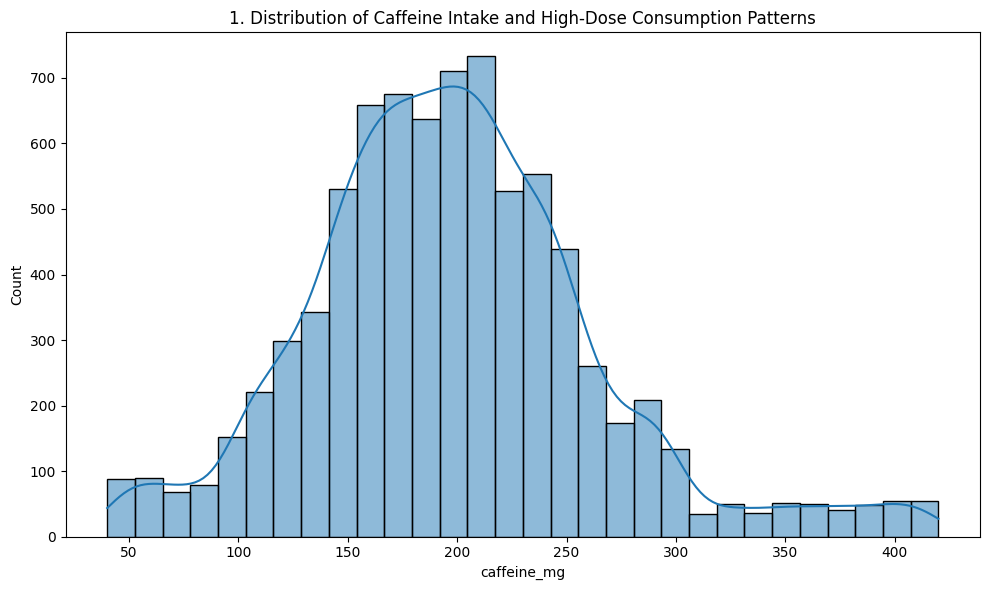

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='caffeine_mg', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Caffeine Intake and High-Dose Consumption Patterns')
show_fig()
plot_no += 1

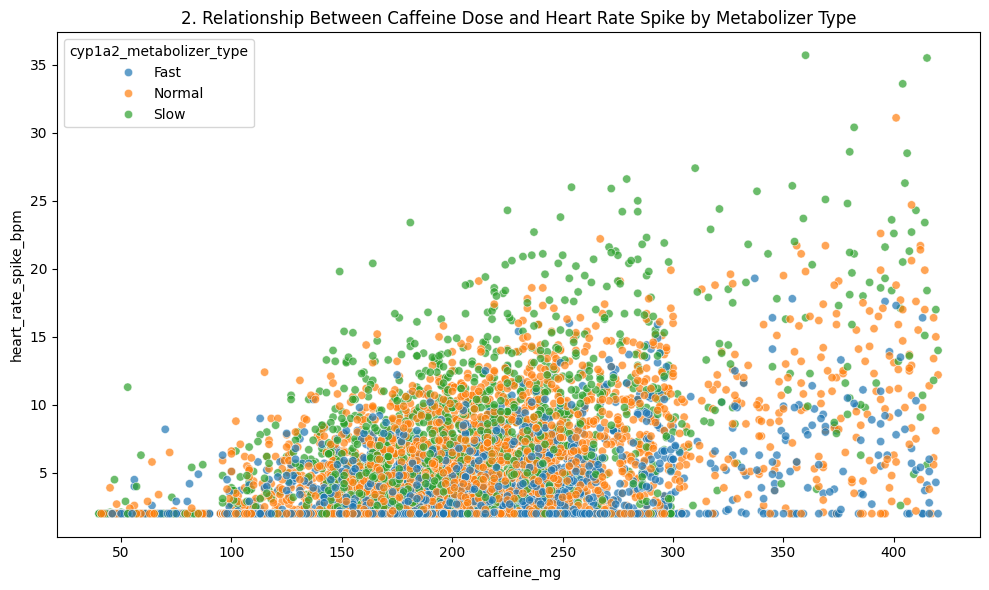

In [14]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='caffeine_mg', y='heart_rate_spike_bpm', hue='cyp1a2_metabolizer_type', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Caffeine Dose and Heart Rate Spike by Metabolizer Type')
show_fig()
plot_no += 1

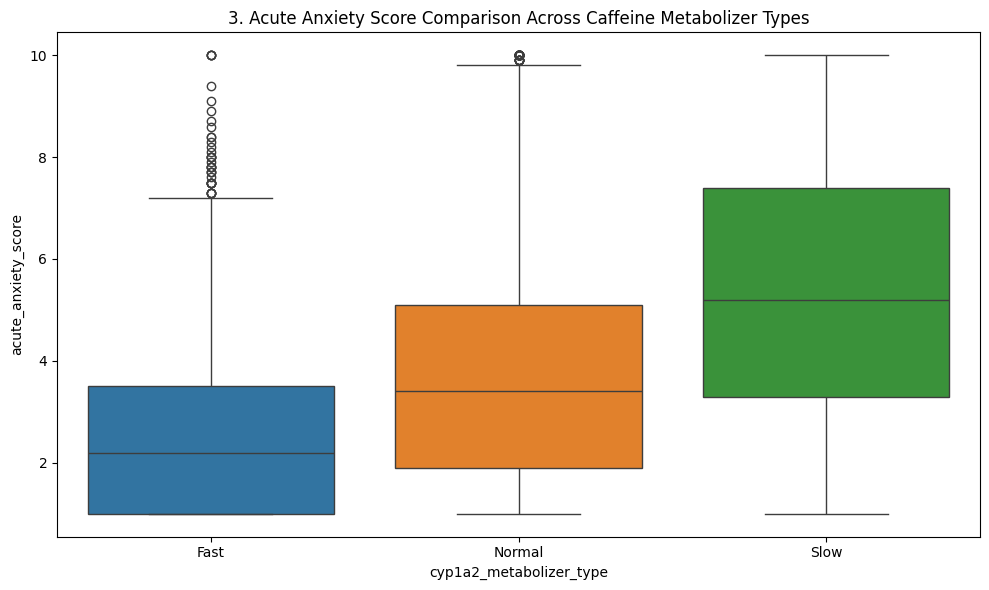

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='cyp1a2_metabolizer_type', y='acute_anxiety_score', hue='cyp1a2_metabolizer_type', legend=False)
plt.title(f'{plot_no}. Acute Anxiety Score Comparison Across Caffeine Metabolizer Types')
show_fig()
plot_no += 1

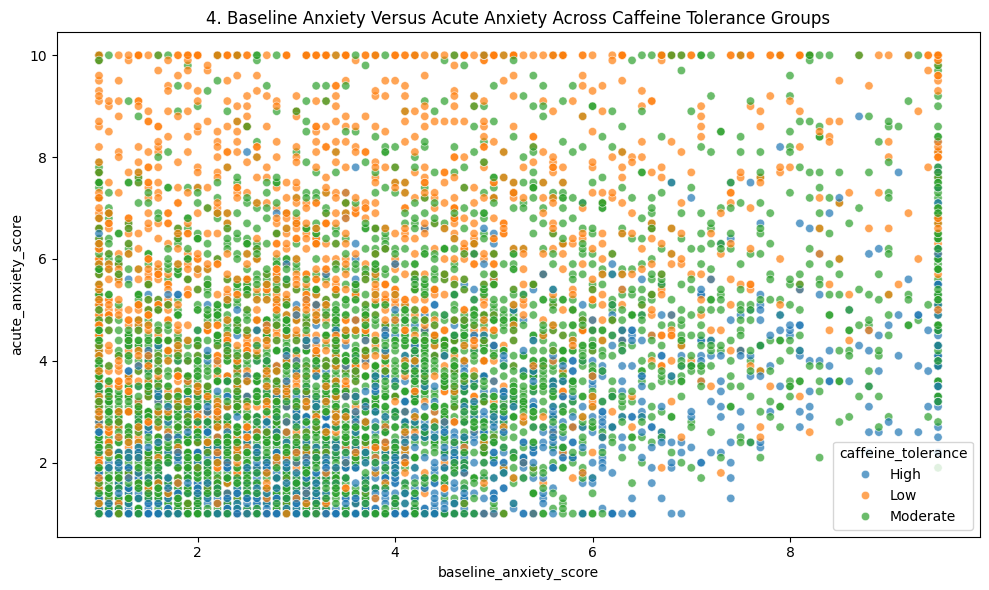

In [16]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='baseline_anxiety_score', y='acute_anxiety_score', hue='caffeine_tolerance', alpha=0.7)
plt.title(f'{plot_no}. Baseline Anxiety Versus Acute Anxiety Across Caffeine Tolerance Groups')
show_fig()
plot_no += 1

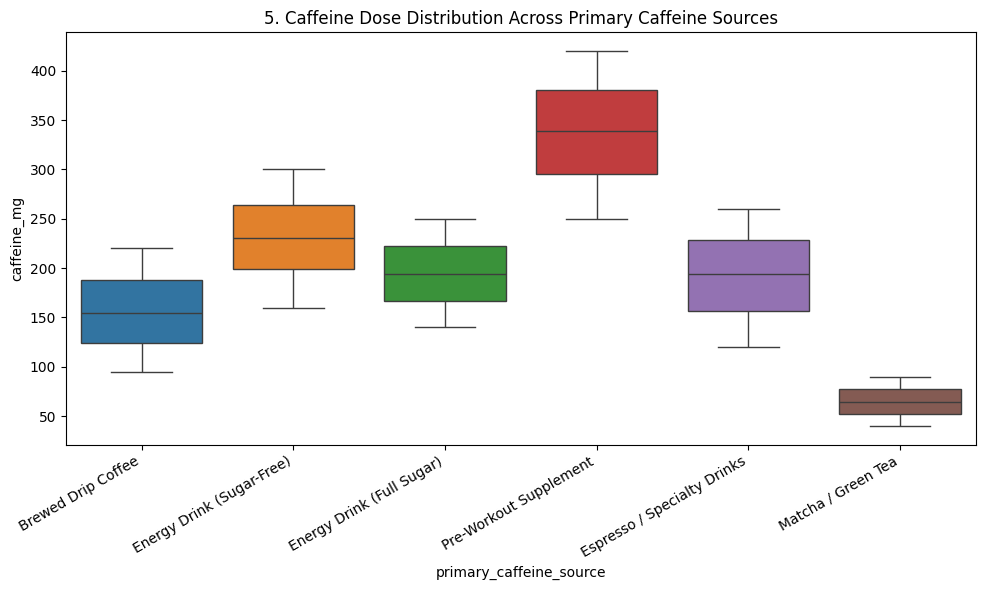

In [17]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='primary_caffeine_source', y='caffeine_mg', hue='primary_caffeine_source', legend=False)
plt.title(f'{plot_no}. Caffeine Dose Distribution Across Primary Caffeine Sources')
plt.xticks(rotation=30, ha='right')
show_fig()
plot_no += 1

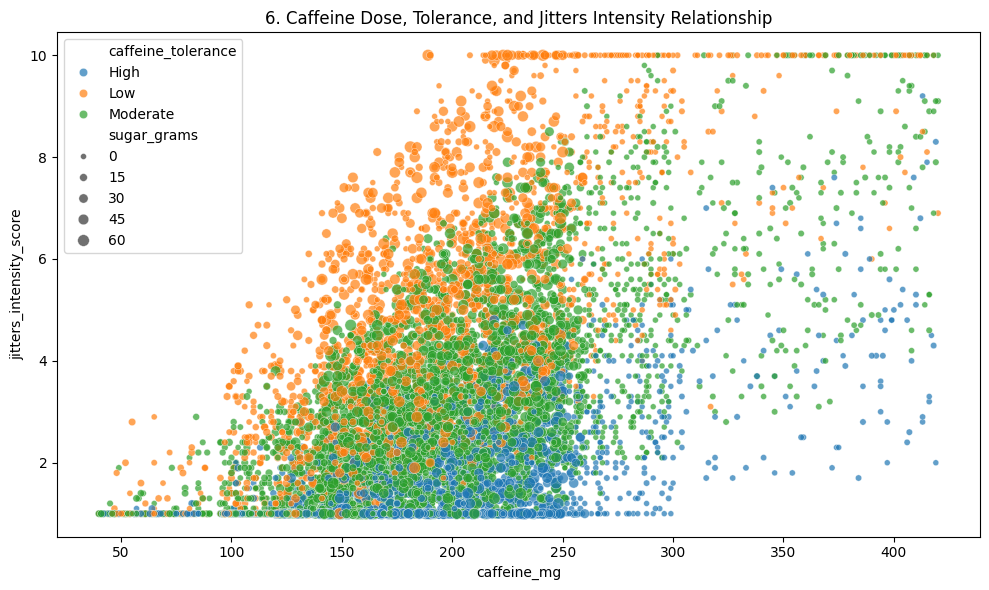

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='caffeine_mg', y='jitters_intensity_score', hue='caffeine_tolerance', size='sugar_grams', alpha=0.7)
plt.title(f'{plot_no}. Caffeine Dose, Tolerance, and Jitters Intensity Relationship')
show_fig()
plot_no += 1

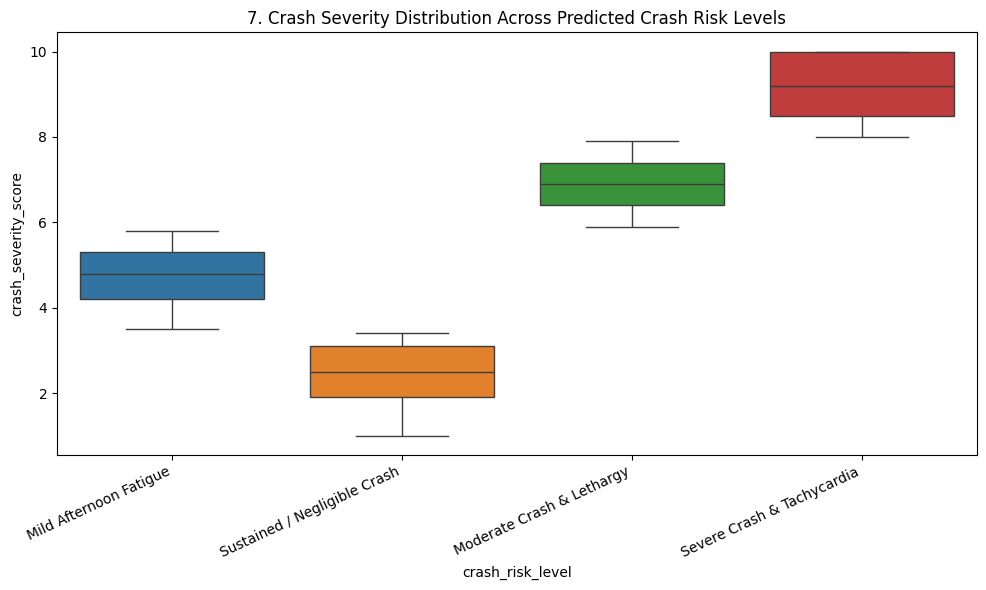

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='crash_risk_level', y='crash_severity_score', hue='crash_risk_level', legend=False)
plt.title(f'{plot_no}. Crash Severity Distribution Across Predicted Crash Risk Levels')
plt.xticks(rotation=25, ha='right')
show_fig()
plot_no += 1

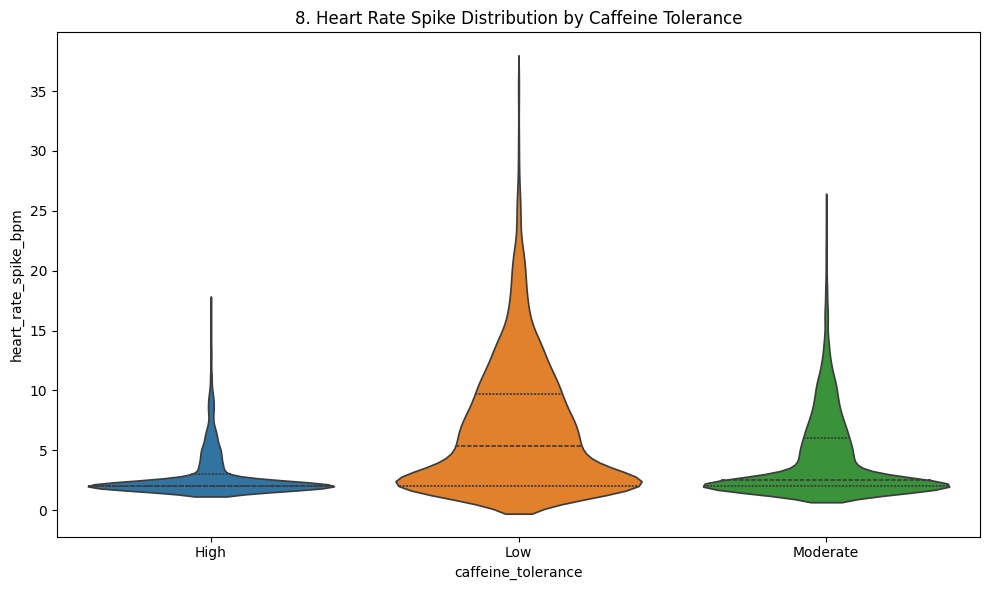

In [20]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='caffeine_tolerance', y='heart_rate_spike_bpm', hue='caffeine_tolerance', legend=False, inner='quartile')
plt.title(f'{plot_no}. Heart Rate Spike Distribution by Caffeine Tolerance')
show_fig()
plot_no += 1

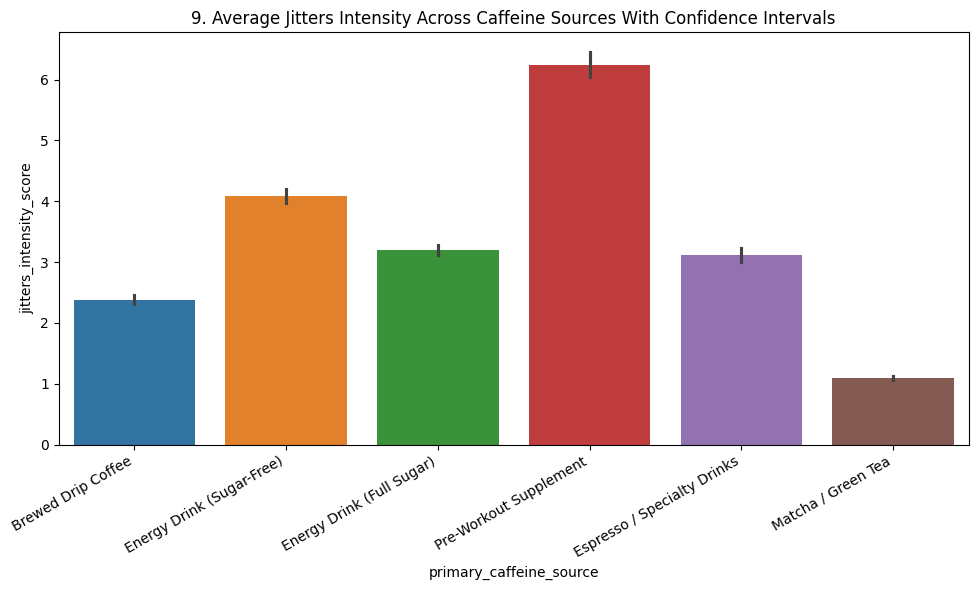

In [21]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='primary_caffeine_source', y='jitters_intensity_score', hue='primary_caffeine_source', legend=False, errorbar=('ci', 95))
plt.title(f'{plot_no}. Average Jitters Intensity Across Caffeine Sources With Confidence Intervals')
plt.xticks(rotation=30, ha='right')
show_fig()
plot_no += 1

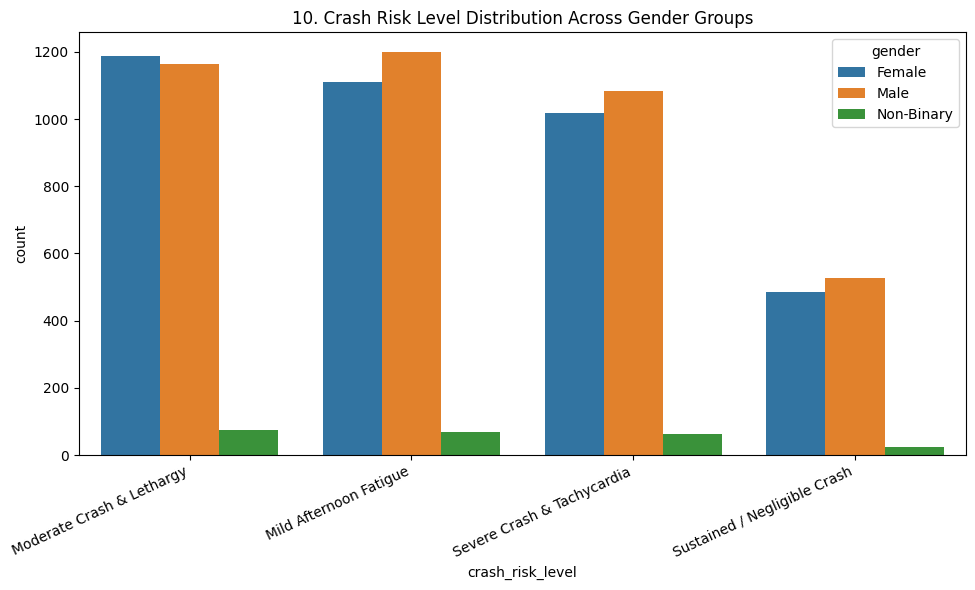

In [22]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='crash_risk_level', hue='gender', order=df['crash_risk_level'].value_counts().index)
plt.title(f'{plot_no}. Crash Risk Level Distribution Across Gender Groups')
plt.xticks(rotation=25, ha='right')
show_fig()
plot_no += 1

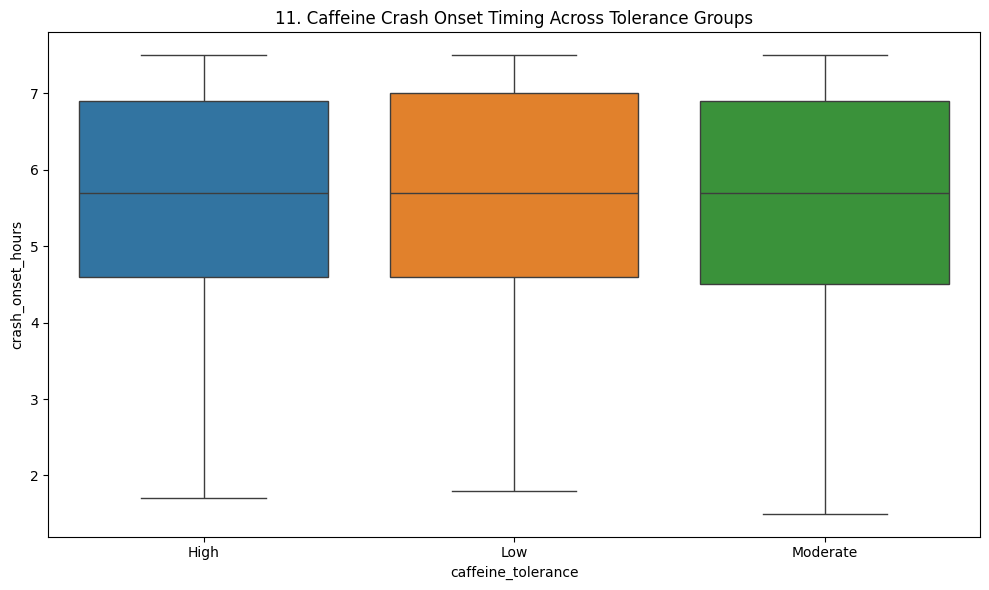

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='caffeine_tolerance', y='crash_onset_hours', hue='caffeine_tolerance', legend=False)
plt.title(f'{plot_no}. Caffeine Crash Onset Timing Across Tolerance Groups')
show_fig()
plot_no += 1

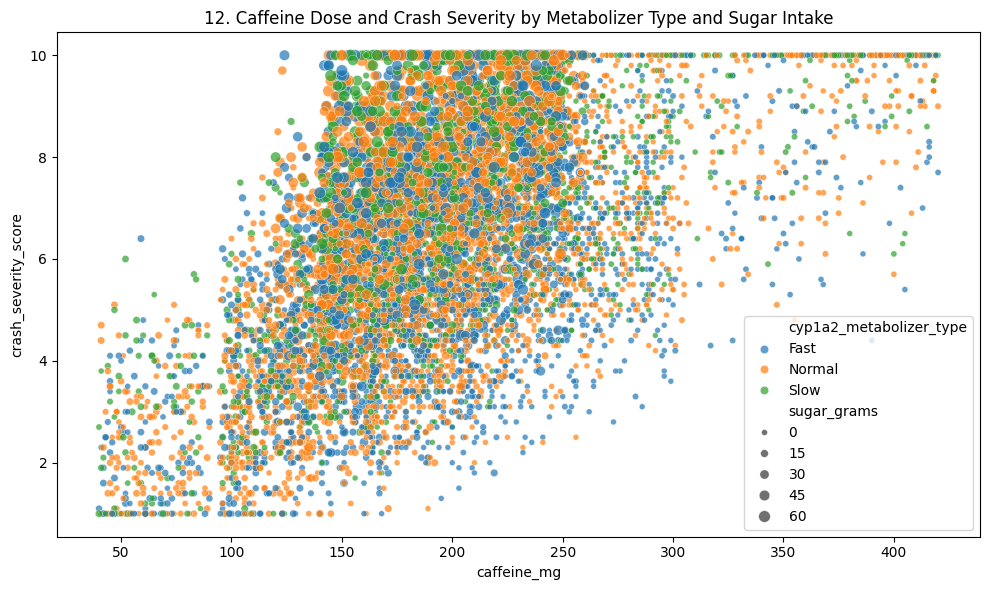

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='caffeine_mg', y='crash_severity_score', hue='cyp1a2_metabolizer_type', size='sugar_grams', alpha=0.7)
plt.title(f'{plot_no}. Caffeine Dose and Crash Severity by Metabolizer Type and Sugar Intake')
show_fig()
plot_no += 1

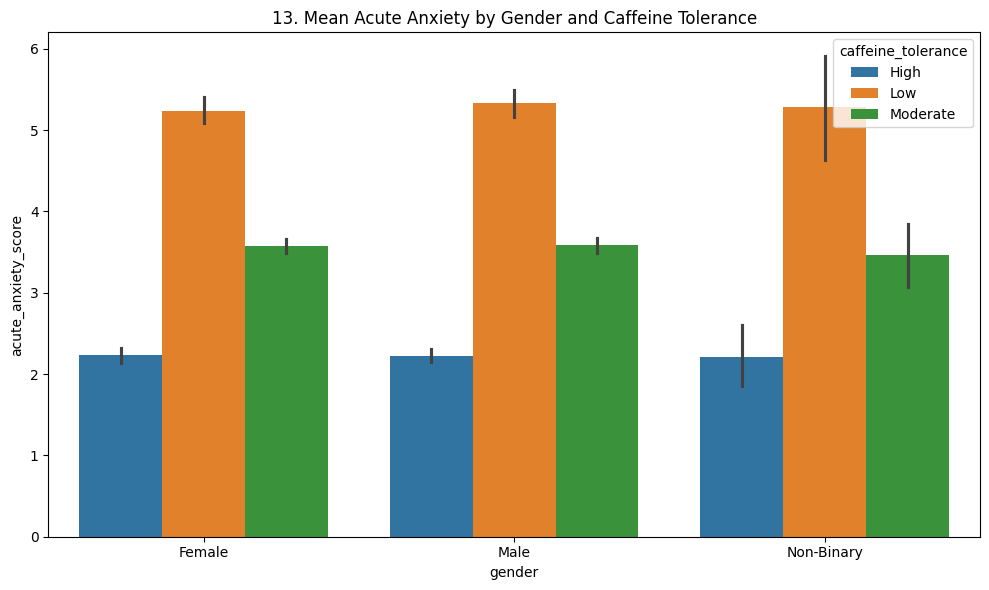

In [25]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='gender', y='acute_anxiety_score', hue='caffeine_tolerance', errorbar=('ci', 95))
plt.title(f'{plot_no}. Mean Acute Anxiety by Gender and Caffeine Tolerance')
show_fig()
plot_no += 1

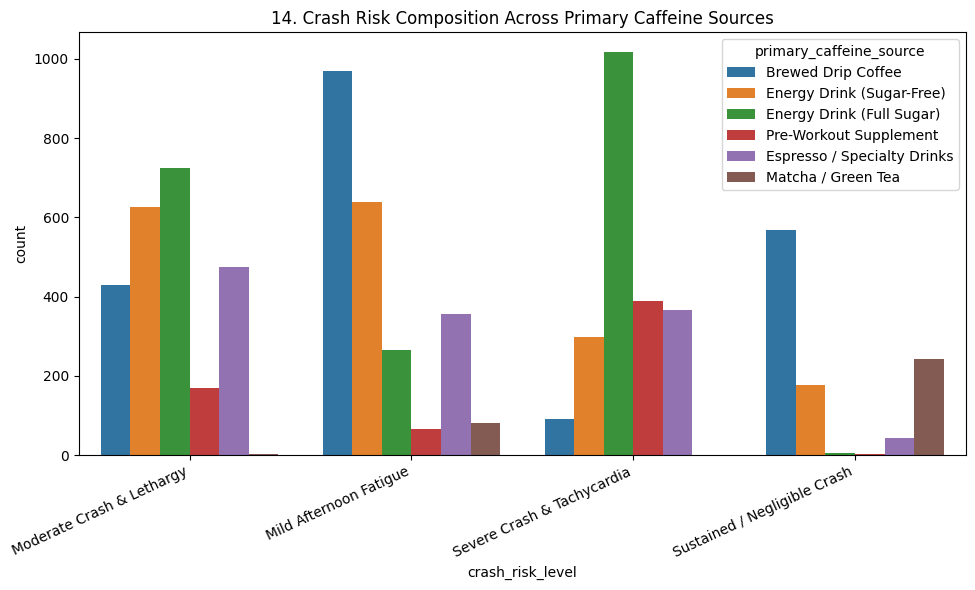

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='crash_risk_level', hue='primary_caffeine_source', order=df['crash_risk_level'].value_counts().index)
plt.title(f'{plot_no}. Crash Risk Composition Across Primary Caffeine Sources')
plt.xticks(rotation=25, ha='right')
show_fig()
plot_no += 1

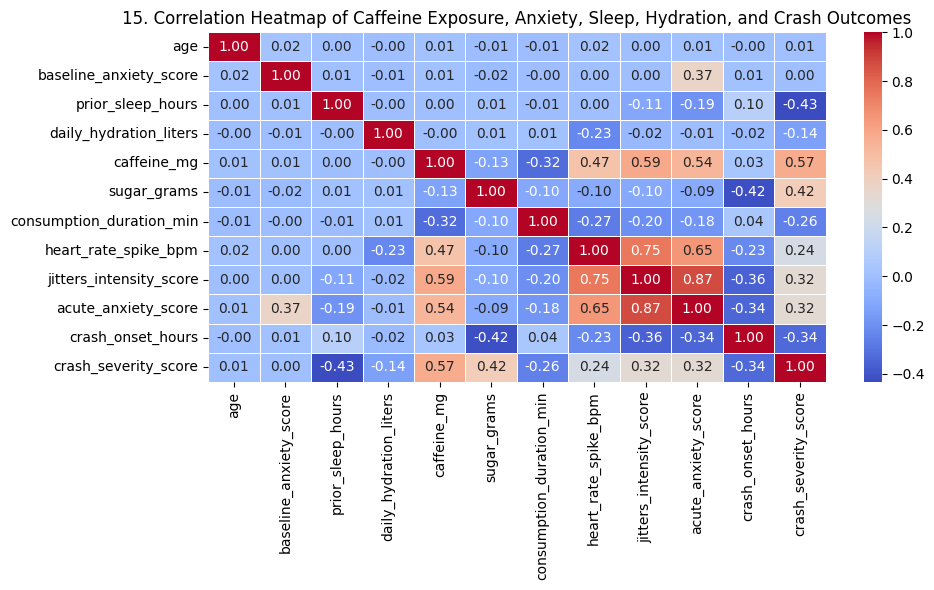

In [27]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').drop(columns=['user_id'], errors='ignore').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Caffeine Exposure, Anxiety, Sleep, Hydration, and Crash Outcomes')
show_fig()
plot_no += 1

# Model Training

## Machine Learning

### Prepare features and predict crash severity

In [28]:
data = df.drop(columns=['user_id', 'crash_severity_score'], errors='ignore').copy()
target = df['crash_severity_score']
valid = target.notna()
data, target = data.loc[valid], target.loc[valid]

### Separate numerical and categorical columns

In [29]:
num_cols = data.select_dtypes(include=np.number).columns.tolist()
cat_cols = data.select_dtypes(exclude=np.number).columns.tolist()

### Build preprocessing pipelines

In [30]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

### Split the dataset into training and testing sets

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.2, random_state=42
)

### Train the gradient boosting regression model

In [32]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.08, max_leaf_nodes=31,
        l2_regularization=1.0, random_state=42
    ))
])
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Generate predictions and evaluate model performance

In [33]:
y_pred = model.predict(X_test)
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

R² Score: 0.9586
MAE: 0.3941
RMSE: 0.4870


### Plot actual versus predicted crash severity

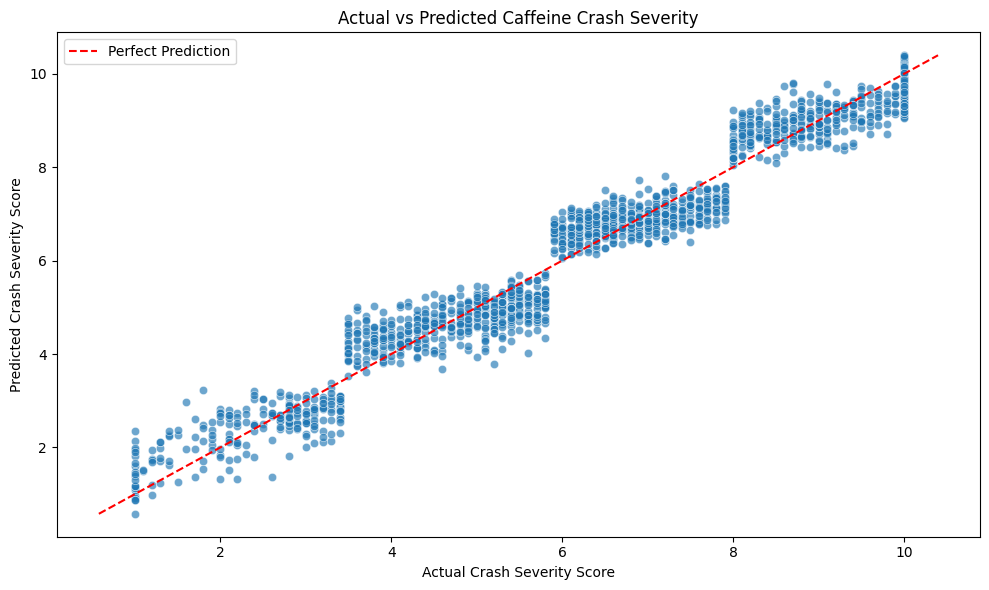

In [34]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.65)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], 'r--', label='Perfect Prediction')
plt.xlabel('Actual Crash Severity Score')
plt.ylabel('Predicted Crash Severity Score')
plt.title('Actual vs Predicted Caffeine Crash Severity')
plt.legend()
show_fig()

## Deep Learning

### Prepare features and target

In [35]:
X = df.drop(columns=['user_id', 'crash_severity_score'], errors='ignore').copy()
y = pd.to_numeric(df['crash_severity_score'], errors='coerce')
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

### Identify numerical and categorical columns

In [36]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

### Split the dataset into training and testing sets

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### Preprocess numerical and categorical features

In [38]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

### Transform features for neural network training

In [39]:
X_train = preprocessor.fit_transform(X_train).astype('float32')
X_test = preprocessor.transform(X_test).astype('float32')
y_train = y_train.to_numpy(dtype='float32')
y_test = y_test.to_numpy(dtype='float32')

### Set reproducible training results

In [40]:
tf.keras.utils.set_random_seed(42)

### Build a deep learning regression model

In [41]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.15),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

### Compile the model

In [42]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

### Configure training callbacks

In [43]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

### Train the deep learning model

In [44]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/150
160/160 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 3.5242 - mae: 1.3045 - val_loss: 6.0079 - val_mae: 2.1061 - learning_rate: 0.0010
Epoch 2/150
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.9458 - mae: 0.7631 - val_loss: 0.9214 - val_mae: 0.7863 - learning_rate: 0.0010
Epoch 3/150
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.7434 - mae: 0.6820 - val_loss: 0.4088 - val_mae: 0.5212 - learning_rate: 0.0010
Epoch 4/150
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.6637 - mae: 0.6446 - val_loss: 0.4045 - val_mae: 0.5119 - learning_rate: 0.0010
Epoch 5/150
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5890 - mae: 0.6100 - val_loss: 0.3706 - val_mae: 0.4988 - learning_rate: 0.0010
Epoch 6/150
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5237 - mae: 0.5796 - val_loss: 0.3852 - val_mae: 0.5085 - learning_rate: 0.0010
Epoch 7/150
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.5148 - mae: 0.5732 - val_loss: 0.3538 - val_mae: 0.4887 - learning_rate: 0.0010

### Predict crash severity on unseen test data

In [45]:
y_pred = model.predict(X_test, verbose=0).flatten()

### Print regression performance metrics

In [46]:
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

R² Score: 0.9497
MAE: 0.4295
RMSE: 0.5368


### Plot actual versus predicted values

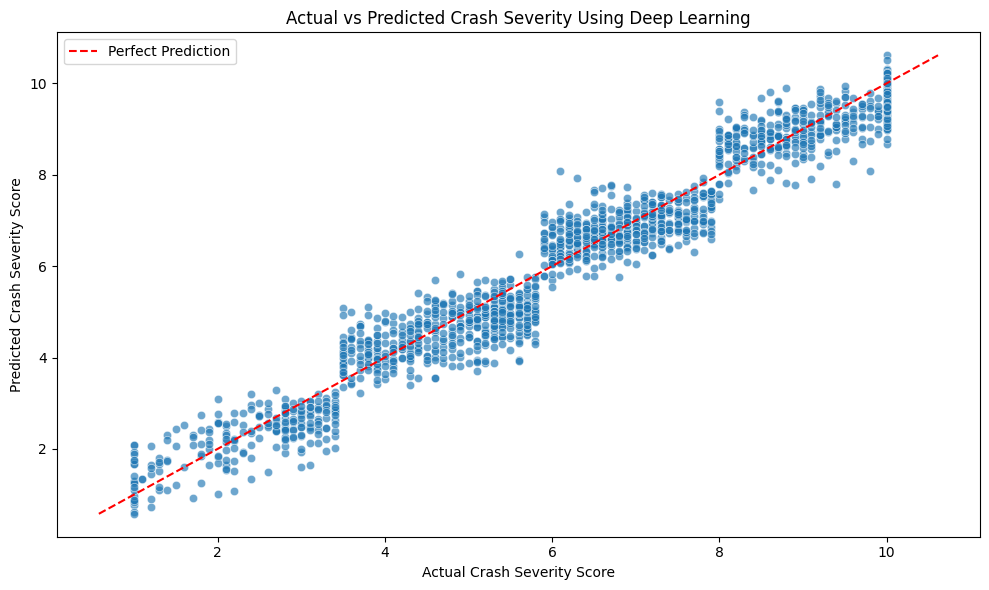

In [47]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.65)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], 'r--', label='Perfect Prediction')
plt.xlabel('Actual Crash Severity Score')
plt.ylabel('Predicted Crash Severity Score')
plt.title('Actual vs Predicted Crash Severity Using Deep Learning')
plt.legend()
show_fig()

### Plot training and validation loss

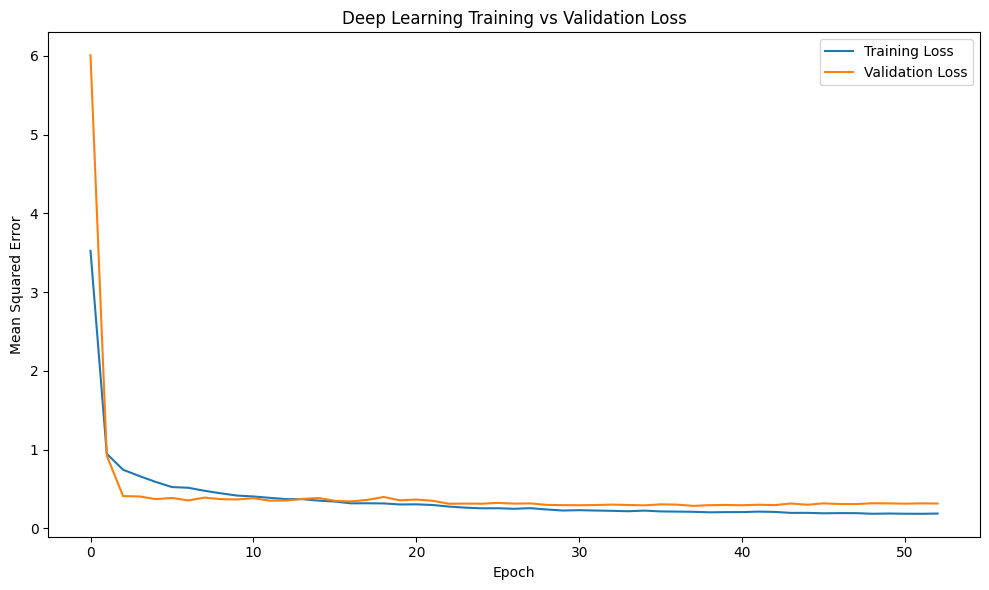

In [48]:
fig = plt.figure(figsize=(10,6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('Deep Learning Training vs Validation Loss')
plt.legend()
show_fig()

In [49]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │           7,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 156,677 (612.02 KB)

 Trainable params: 51,969 (203.00 KB)

 Non-trainable params: 768 (3.00 KB)

 Optimizer params: 103,940 (406.02 KB)